In [102]:
#!pip install librosa numpy pandas scipy

In [117]:
import os
import librosa
import numpy as np

# Path to your dataset folder
DATASET_PATH = "Dataset_wav/"

# Function to load all audio files and assign labels
def load_audio_files(dataset_path):
    data = []
    labels = []

    for label in os.listdir(dataset_path):
        label_path = os.path.join(dataset_path, label)
        if not os.path.isdir(label_path):
            continue

        for file in os.listdir(label_path):
            if file.endswith(".wav"):
                file_path = f"{label_path}/{file}"
                #file_path = os.path.join(label_path, file)
                #print(file_path)

                try:
                    audio, sr = librosa.load(file_path, sr=None)  # sr=None keeps original sample rate
                    data.append(audio)
                    labels.append(label)
                except Exception as e:
                    print(f"Error loading {file_path}: {e}")

    return data, labels

audio_data, audio_labels = load_audio_files(DATASET_PATH)
print(f"Loaded {len(audio_data)} samples.")


Loaded 82 samples.


In [119]:
# Sample rate
sr = 44100
cutoff_samples = sr  # 1 second

# Cut first second from all audio samples
cut_audio_data = []

for audio in audio_data:
    if len(audio) > cutoff_samples:
        cut_audio = audio[cutoff_samples:]  # Remove first second
    else:
        cut_audio = audio  # If too short, keep as is
    cut_audio_data.append(cut_audio)

# Replace or keep copy
audio_data = cut_audio_data
print(f"Trimmed first second from {len(audio_data)} audio samples.")


Trimmed first second from 82 audio samples.


In [105]:
from scipy.signal import butter, lfilter

def butter_bandpass(lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return b, a

def apply_bandpass_filter(data, lowcut, highcut, fs):
    b, a = butter_bandpass(lowcut, highcut, fs)
    return lfilter(b, a, data)


In [106]:
# === Filter parameters ===
lowcut = 300    # Hz
highcut = 3000  # Hz
sr = 44100      # sample rate

# === Apply filter only to Wine and Beer ===
filtered_audio_data = []

for audio, label in zip(audio_data, audio_labels):
    if label != "Oil":
        filtered = apply_bandpass_filter(audio, lowcut, highcut, sr)
    else:
        filtered = audio  # Keep oil unfiltered
    filtered_audio_data.append(filtered)

print(f"Processed {len(filtered_audio_data)} audio samples.")

# Optionally keep a copy of raw data
raw_audio_data = audio_data
audio_data = filtered_audio_data


Processed 82 audio samples.


In [107]:
from IPython.display import Audio

# === Find first Oil sample ===
oil_index = audio_labels.index("Beer")

# === Get raw and filtered audio ===
raw_oil = raw_audio_data[oil_index]
filtered_oil = apply_bandpass_filter(raw_oil, 700, 4000, 44100)

# === Play filtered audio ===
print("🎧 Filtered Oil Sample:")
Audio(filtered_oil, rate=44100)



🎧 Filtered Oil Sample:


In [108]:
Audio(raw_oil, rate=44100)

In [120]:
def segment_audio(audio, sr, window_size=2.0, overlap=0.5):
    segments = []
    samples_per_window = int(window_size * sr)
    step_size = int(samples_per_window * (1 - overlap))

    for start in range(0, len(audio) - samples_per_window + 1, step_size):
        end = start + samples_per_window
        segment = audio[start:end]
        segments.append(segment)

    return segments


In [121]:
segmented_audio = []
segmented_labels = []

window_size = 2.0  # seconds
overlap = 0.5

for audio, label in zip(audio_data, audio_labels):
    sr = 44100  # Your WAV files are at 44.1kHz after conversion
    segments = segment_audio(audio, sr, window_size, overlap)

    for segment in segments:
        segmented_audio.append(segment)
        segmented_labels.append(label)

print(f"Total segments created: {len(segmented_audio)}")
print(f"Example segment shape: {segmented_audio[0].shape}")
print(f"Labels example: {segmented_labels[:15]}")


Total segments created: 230
Example segment shape: (88200,)
Labels example: ['Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer']


In [122]:
def extract_features(segment, sr):
    # MFCCs
    mfccs = librosa.feature.mfcc(y=segment, sr=sr, n_mfcc=13)
    mfccs_mean = np.mean(mfccs, axis=1)

    # Spectral Centroid
    centroid = np.mean(librosa.feature.spectral_centroid(y=segment, sr=sr))

    # Spectral Bandwidth
    bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=segment, sr=sr))

    # Spectral Contrast
    contrast = np.mean(librosa.feature.spectral_contrast(y=segment, sr=sr))

    # Zero Crossing Rate
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=segment))

    # Combine all features into one array
    features = np.hstack([mfccs_mean, centroid, bandwidth, contrast, zcr])
    return features


In [123]:
all_features = []
all_labels_clean = []

sr = 44100  # Same sample rate as before

for segment, label in zip(segmented_audio, segmented_labels):
    features = extract_features(segment, sr)
    all_features.append(features)
    all_labels_clean.append(label)

all_features = np.array(all_features)
all_labels_clean = np.array(all_labels_clean)

print("Feature extraction complete!")
print("Feature shape:", all_features.shape)
print("Labels shape:", all_labels_clean.shape)


Feature extraction complete!
Feature shape: (230, 17)
Labels shape: (230,)


In [124]:
import pandas as pd

feature_columns = [f"mfcc_{i+1}" for i in range(13)] + ["centroid", "bandwidth", "contrast", "zcr"]

df = pd.DataFrame(all_features, columns=feature_columns)
df['label'] = all_labels_clean

df.to_csv("liquid_audio_features.csv", index=False)
print("✅ Feature dataset saved as 'liquid_audio_features.csv'")


✅ Feature dataset saved as 'liquid_audio_features.csv'


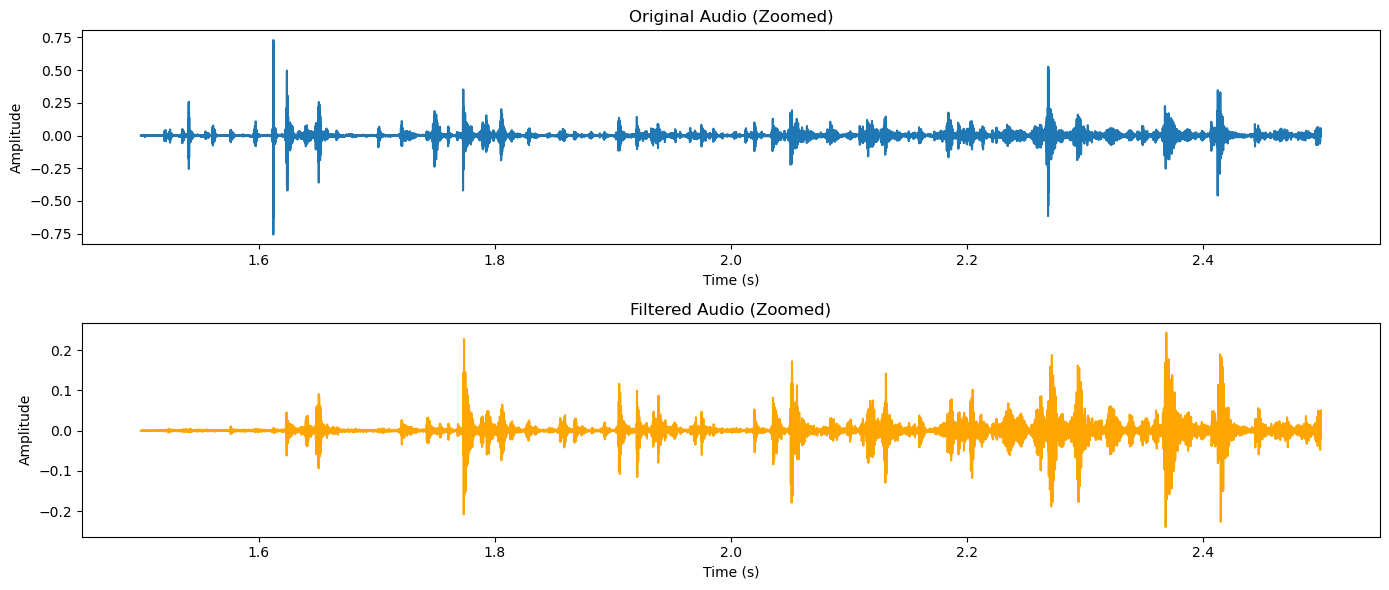

In [114]:
# Zoom range in seconds
start_time = 1.5
end_time = 2.5

# Convert to samples
start_sample = int(start_time * sr)
end_sample = int(end_time * sr)

# Slice both signals
raw_zoom = raw_audio[start_sample:end_sample]
filtered_zoom = filtered_audio[start_sample:end_sample]
time_zoom = np.linspace(start_time, end_time, end_sample - start_sample)

# Plot zoomed in waveforms
plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(time_zoom, raw_zoom)
plt.title("Original Audio (Zoomed)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
plt.plot(time_zoom, filtered_zoom, color='orange')
plt.title("Filtered Audio (Zoomed)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()


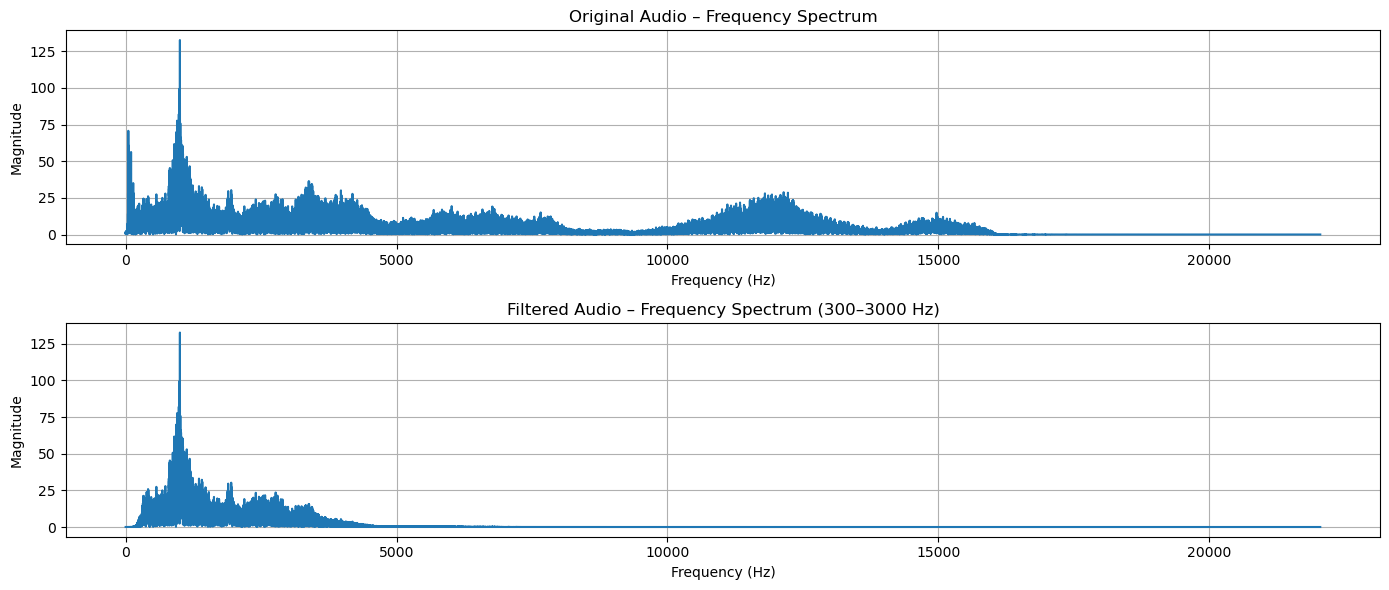

In [115]:
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, sr, title=""):
    N = len(signal)
    yf = fft(signal)
    xf = fftfreq(N, 1 / sr)

    # Use only the positive frequencies
    idx = np.where(xf >= 0)
    xf = xf[idx]
    yf = np.abs(yf[idx])

    plt.plot(xf, yf)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.grid(True)

# Zoom into just the first 4 seconds to focus on the pouring
raw_cut = raw_audio[:4 * sr]
filtered_cut = filtered_audio[:4 * sr]

plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plot_frequency_spectrum(raw_cut, sr, "Original Audio – Frequency Spectrum")

plt.subplot(2, 1, 2)
plot_frequency_spectrum(filtered_cut, sr, "Filtered Audio – Frequency Spectrum (300–3000 Hz)")

plt.tight_layout()
plt.show()


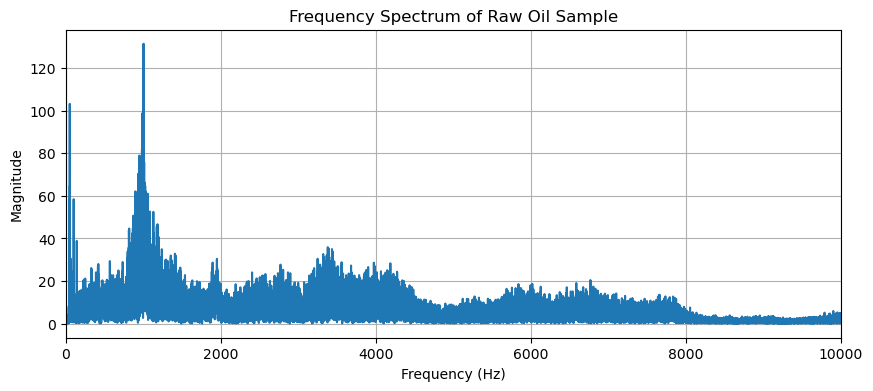

In [116]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# === Step 1: Get first Oil sample ===
oil_index = audio_labels.index("Beer")
raw_oil = raw_audio_data[oil_index]
sr = 44100

# === Step 2: Cut to first few seconds for focus (optional) ===
raw_oil_cut = raw_oil[:4 * sr]  # First 4 seconds

# === Step 3: FFT and plot ===
def plot_frequency_spectrum(signal, sr, title=""):
    N = len(signal)
    yf = fft(signal)
    xf = fftfreq(N, 1 / sr)

    # Use only the positive frequencies
    idx = np.where(xf >= 0)
    xf = xf[idx]
    yf = np.abs(yf[idx])

    plt.figure(figsize=(10, 4))
    plt.plot(xf, yf)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.grid(True)
    plt.xlim(0, 10000)  # Limit for visibility
    plt.show()

# === Plot it ===
plot_frequency_spectrum(raw_oil_cut, sr, "Frequency Spectrum of Raw Oil Sample")
